<a href="https://colab.research.google.com/github/lorinrealon/spotify-global-trends-2026/blob/main/spotify_global_trends_2026_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Spotify Global Trends 2026 Analysis**
### **Project Overview**

This project explores **Spotify Global Trends 2026** data (`spotify_global_trends_final.csv`, sourced from [Kaggle](https://www.kaggle.com/datasets/mkaur1141/spotify-global-top-songs-2026)) to understand how viral popularity relates to long-term chart staying power across different music genres. Using **Python**, **Pandas**, **SQLite**, and **Seaborn**, the analysis examines genre-level virality (`viral_score`), chart duration (`days`), and outlier tracks that achieve sustained longevity without massive viral spikes.

---



# **What is the Objective?**

- Which 3 genres gained the highest average `viral_score` (among genres with at least 10 tracks)?
- Within those top 3 genres, does genre affect how many days a song stays on the chart?
- Are there specific songs that stayed on the chart for an unusually long time (top 10% of days) despite having a below-average `viral_score`, and which genres do those tracks belong to?

# **Get the Data**

In [1]:
# Import required libraries for data manipulation, SQL querying, and visualization
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import sqlite3

# Load the Spotify dataset from CSV into a Pandas DataFrame
spotify_filepath = "/content/spotify_global_trends_2026 - spotify_global_trends_final.csv"
spotify_data = pd.read_csv(spotify_filepath)

spotify_data

# Create an in-memory SQLite database and load the DataFrame as a SQL table
conn=sqlite3.connect(':memory')
spotify_data.to_sql('spotify_data', conn, index=False, if_exists='replace')

# Apply a consistent visual theme and color palette across all charts
sns.set_theme(style='whitegrid', palette='viridis')

# **Quick Look at the Data**

In [2]:
# The first few records

spotify_data.head()

,track_name,artist_name,streams,stream_change,7day,genre,country,pos,days,viral_score,trend,popularity_category,longevity
0,SWIM,BTS,11273830,-3370522,25918182,K-Pop,KR,1,2,37192012,Falling,Trending,New
1,Body to Body,BTS,6815694,-4369341,18000729,K-Pop,KR,2,2,24816423,Falling,Trending,New
2,Babydoll,Dominic Fike,5733862,178968,36599831,Alternative Pop,Florida,3,119,42333693,Rising,Trending,Evergreen
3,Hooligan,BTS,5338608,-3396855,14074071,K-Pop,KR,4,2,19412679,Falling,Trending,New
4,FYA,BTS,5196767,-2873904,13267438,K-Pop,KR,5,2,18464205,Falling,Trending,New


In [3]:
# The last few records

spotify_data.tail()

,track_name,artist_name,streams,stream_change,7day,genre,country,pos,days,viral_score,trend,popularity_category,longevity
173,The Chain - 2004 Remaster,Fleetwood Mac,1210598,-79537,8817306,Rock,GB,196,205,10027904,Falling,Average,Evergreen
174,Love On The Brain,Rihanna,1203160,-69820,7439269,Soul,US,197,352,8642429,Falling,Average,Evergreen
175,Sign of the Times,Harry Styles,1198929,-121566,3816744,Pop,England,198,331,5015673,Falling,Average,Evergreen
176,Sorry,Justin Bieber,1192146,-86760,7346804,Pop,CA,199,767,8538950,Falling,Average,Evergreen
177,Life Goes On,BTS,1191777,-76127,8979038,K-Pop,KR,200,207,10170815,Falling,Average,Evergreen


In [4]:
# A random sample

spotify_data.sample(n=5) # or frac=0.2

,track_name,artist_name,streams,stream_change,7day,genre,country,pos,days,viral_score,trend,popularity_category,longevity
132,Africa,TOTO,1350745,-23426,7537107,Rock,US,141,753,8887852,Falling,Average,Evergreen
88,The Less I Know The Better,Tame Impala,1593781,-51333,10870662,Psychedelic Rock,AU,96,510,12464443,Falling,Average,Evergreen
101,Midnight Sun,Zara Larsson,1512185,-10911,10133254,Dance-Pop,SE,109,63,11645439,Falling,Average,Stable Hit
89,505,Arctic Monkeys,1587695,-113645,11653237,Indie Rock,GB,97,1537,13240932,Falling,Average,Evergreen
129,Sweet Child O' Mine,Guns N' Roses,1367839,-13859,8983873,Hard Rock,US,138,440,10351712,Falling,Average,Evergreen


In [5]:
# The names of the columns

spotify_data.columns

Index(['track_name', 'artist_name', 'streams', 'stream_change', '7day',
       'genre', 'country', 'pos', 'days', 'viral_score', 'trend',
       'popularity_category', 'longevity'],
      dtype='object')

In [6]:
# The datatypes

spotify_data.dtypes

,0
track_name,object
artist_name,object
streams,int64
stream_change,int64
7day,int64
genre,object
country,object
pos,int64
days,int64
viral_score,int64


In [7]:
# A statistical summary

spotify_data.describe()

,streams,stream_change,7day,pos,days,viral_score
count,1.780000e+02,1.780000e+02,1.780000e+02,178.000000,178.000000,1.780000e+02
mean,2.093366e+06,-2.719877e+05,1.244096e+07,96.123596,536.275281,1.453433e+07
std,1.277789e+06,7.528285e+05,5.786175e+06,56.151997,617.572830,6.699639e+06
min,1.191777e+06,-4.369341e+06,2.523194e+06,1.000000,2.000000,3.774959e+06
25%,1.350050e+06,-1.267320e+05,9.277907e+06,48.250000,80.000000,1.067544e+07
50%,1.590738e+06,-7.408450e+04,1.080256e+07,96.500000,346.500000,1.257072e+07
75%,2.202585e+06,-5.174750e+03,1.354278e+07,141.750000,766.250000,1.608216e+07
max,1.127383e+07,1.899990e+05,3.659983e+07,200.000000,3070.000000,4.233369e+07


# **Clean/Fix the Data**

In [8]:
# Inspect dataset dimensions, data types, and confirm the data is already clean (no missing values)
print(spotify_data.shape)
print(spotify_data.info())
print(spotify_data.isnull().sum())

(178, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   track_name           178 non-null    object
 1   artist_name          178 non-null    object
 2   streams              178 non-null    int64 
 3   stream_change        178 non-null    int64 
 4   7day                 178 non-null    int64 
 5   genre                178 non-null    object
 6   country              178 non-null    object
 7   pos                  178 non-null    int64 
 8   days                 178 non-null    int64 
 9   viral_score          178 non-null    int64 
 10  trend                178 non-null    object
 11  popularity_category  178 non-null    object
 12  longevity            178 non-null    object
dtypes: int64(6), object(7)
memory usage: 18.2+ KB
None
track_name             0
artist_name            0
streams                0
stream_change      

The dataset contains 178 rows and 13 columns with 0 missing values, so no additional data cleaning was required.

# **Analysis & Visualizations**

## ***Q1: Which 3 genres gained the highest average `viral_score` (among genres with at least 10 tracks)?***

In [9]:
# Query the top 3 genres with the highest average viral_score with a minimum of 10 tracks
q1_sql = """
         SELECT genre,
                ROUND(AVG(viral_score), 2) AS avg_viral_score,
                COUNT(*) AS track_count
         FROM spotify_data
         GROUP BY genre
         HAVING track_count >= 10
         ORDER BY avg_viral_score DESC
         LIMIT 3
         """
q1_df = pd.read_sql(q1_sql, conn)
q1_df

,genre,avg_viral_score,track_count
0,K-Pop,17553166.40,15
1,Rock,14341186.43,14
2,Pop,13847265.28,53


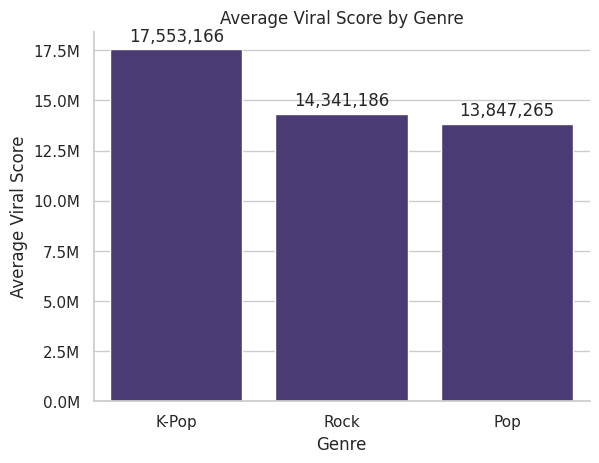

In [10]:
# Plot average viral score for the top 3 genres
ax = sns.barplot(data=q1_df, x='genre', y='avg_viral_score')

# Format y-axis ticks in millions (M) instead of scientific notation
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M'))

# Add title, axis labels, and remove top/right borders
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.title('Average Viral Score by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Viral Score')
sns.despine()
plt.show()

The top three music genres with the highest `viral_score` are K-Pop (17,553,166), Rock (14,341,186), and Pop (13,847,265), each with at least 10 tracks. The `viral_score` measures the popularity of these genres by combining the total number of streams for each song with the streams collected over the past seven days. This calculation highlights their overall impact and momentum in the music industry, with K-Pop taking the lead.

## ***Q2: Within those top 3 genres, does genre affect how many days a song stays on the chart?***

In [11]:
# Calculate average days on chart for the top 3 viral genres from Q1
q2_sql = """
         SELECT genre,
                ROUND(AVG(days), 2) AS avg_days
         FROM spotify_data
         WHERE genre IN (
             SELECT genre
             FROM spotify_data
             GROUP BY genre
             HAVING COUNT(*) >= 10
             ORDER BY AVG(viral_score) DESC
             LIMIT 3
         )
         GROUP BY genre
         ORDER BY avg_days DESC
         """
q2_df = pd.read_sql(q2_sql, conn)
q2_df

,genre,avg_days
0,Rock,736.86
1,Pop,630.57
2,K-Pop,15.67


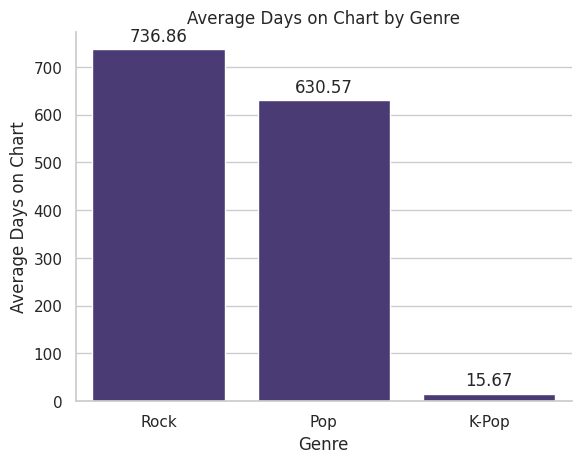

In [12]:
# Plot average days on chart for each of the top 3 genres
ax = sns.barplot(data=q2_df, x='genre', y='avg_days')

# Display exact average days to 2 decimal places above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

# Add title, axis labels, and remove top/right borders
plt.title('Average Days on Chart by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Days on Chart')
sns.despine()
plt.show()

Yes, genre does affect chart longevity among the top three genres. Among these, Rock has the highest average chart duration, remaining on the chart for an average of approximately 736.86 days. Pop follows with an average of 630.57 days, while K-Pop averages only 15.67 days. Despite having the highest average viral score, K-Pop songs typically stay on the chart for only a few days. This indicates that while a genre may have high virality, it does not necessarily mean a song will maintain long-term chart presence. In conclusion, virality alone does not guarantee a song's staying power on the chart.

## ***Q3: Are there specific songs that stayed on the chart for an unusually long time (top 10% of days) despite having a below-average `viral_score`, and which genres do those tracks belong to?***

In [13]:
# Set thresholds: 90th percentile for days (top 10%) and mean viral score
days_cutoff = spotify_data['days'].quantile(0.90)
avg_viral_score = spotify_data['viral_score'].mean()

# Filter for long-staying tracks with below-average viral scores
q3_songs = spotify_data[
    (spotify_data['days'] >= days_cutoff) & (spotify_data['viral_score'] < avg_viral_score)
]

# Count how many qualifying outlier tracks belong to each genre
q3_genres = q3_songs['genre'].value_counts()

# Display the qualifying tracks sorted by longest stay, followed by genre counts
display(q3_songs[['track_name', 'artist_name', 'genre', 'days', 'viral_score']].sort_values(by='days', ascending=False))
display(q3_genres)

,track_name,artist_name,genre,days,viral_score
169,Perfect,Ed Sheeran,Pop,3070,10184687
99,Shape of You,Ed Sheeran,Pop,2815,11796427
71,Riptide,Vance Joy,Rock,2586,13281950
116,Counting Stars,OneRepublic,Pop,2495,10939905
110,Blinding Lights,The Weeknd,R&B,2301,11177852
154,Sunflower - Spider-Man: Into the Spider-Verse ...,Post Malone,Pop,2292,6307042
69,Starboy (w/ Daft Punk),The Weeknd,R&B,2095,14302924
138,Without Me,Eminem,Hip Hop,1637,10490186
89,505,Arctic Monkeys,Indie Rock,1537,13240932
102,When I Was Your Man,Bruno Mars,Pop,1476,11875300


,count
genre,
Pop,6
R&B,2
Rock,1
Indie Rock,1
Hip Hop,1


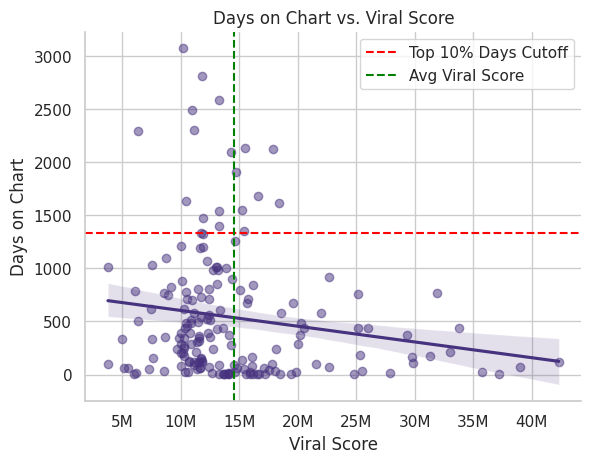

In [14]:
# Plot all songs with a linear regression trendline to show virality vs. longevity
ax = sns.regplot(data=spotify_data, x='viral_score', y='days', scatter_kws={'alpha': 0.5})

# Format x-axis ticks in millions (M) for readability
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))

# Highlight the top 10% days and average viral score thresholds
plt.axhline(days_cutoff, color='red', linestyle='--', label='Top 10% Days Cutoff')
plt.axvline(avg_viral_score, color='green', linestyle='--', label='Avg Viral Score')

# Add legend, title, axis labels, and remove top/right borders
plt.legend()
plt.title('Days on Chart vs. Viral Score')
plt.xlabel('Viral Score')
plt.ylabel('Days on Chart')
sns.despine()
plt.show()

There were 11 tracks that remained in the top 10% of the chart for a significant number of days, despite having below-average viral scores. Notable examples include "Perfect" and "Shape of You" by Ed Sheeran, as well as "Riptide" by Vance Joy. Of these tracks, 6 belong to the Pop genre, 2 to R&B, and 1 each to Rock, Indie Rock, and Hip Hop. Additionally, the regression plot indicates an inverse relationship between the number of days on the chart and the viral score. As the viral score increases, the number of days on the chart decreases. This suggests that some tracks succeed through gradual and consistent listening rather than through a sudden viral spike.

# **Conclusion**

In 2026, high initial virality on Spotify did not automatically guarantee long-term chart longevity.

### **Key Findings**
- K-Pop (17,553,166), Rock (14,341,186), and Pop (13,847,265) achieved the highest average viral scores in 2026.
- Within those top 3 genres, Rock stayed on the chart longest at an average of 736.86 days, compared to 630.57 days for Pop and 15.67 days for K-Pop.
- 11 songs reached the top 10% of chart duration despite having a below-average viral score, led primarily by Pop.

### **Takeaway**
- Playlist curators and marketing teams should avoid dropping tracks with modest initial viral scores too early, as certain genres demonstrate strong gradual staying power over time.

### **Limitations & Future Work**
- Scope: Analysis is limited to 2026 chart data; expanding across multiple years would test whether these genre patterns hold over time.
- Next Steps: Incorporating track audio features (e.g., energy, danceability, tempo) could reveal what drives sustained chart performance.